In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, glob, os
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 60)
BLUE = '#2a78d6'

In [2]:
def find(name):
    roots = ['/kaggle/input', os.environ.get('DATA_DIR', '.')]
    for r in roots:
        hits = glob.glob(f'{r}/**/{name}', recursive=True)
        if hits:
            return sorted(hits, key=len)[0]
    raise FileNotFoundError(name)

orders    = pd.read_csv(find('ecommerce_sales_customer_analytics_150k.csv'))
items     = pd.read_csv(find('order_items.csv'))
products  = pd.read_csv(find('product_catalog.csv'))
customers = pd.read_csv(find('customer_master.csv'))
print('orders   ', orders.shape)
print('items    ', items.shape)
print('products ', products.shape)
print('customers', customers.shape)

orders    (138116, 46)
items     (397569, 12)
products  (1175, 9)
customers (25000, 11)


In [3]:
orders.head(3)

,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,3.0,3.0,On Time,NaN,NaN,3.5,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,1350.19,477.89,61.07,12.03,945.40,588.33,345.04,36.50,12459.68,True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,10.0,10.0,On Time,NaN,NaN,3.6,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,3144.64,1456.06,320.83,9.00,2018.41,2031.88,-22.47,-1.11,13032.48,True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,19993,Cash on Delivery,Paid,USD,Express,WH-015,3.0,3.0,On Time,NaN,NaN,4.3,Positive,Good product. Works as expected.,YouTube,NaN,NaN,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,6159.44,True,6


In [4]:
items.head(3)

,order_id,product_id,quantity,unit_price,discount_percentage,discount_amount,gross_sales,tax_amount,shipping_cost,net_sales,product_cost,profit
0,ORD-301242,PROD-000738,2,244.40,0.339607,166.00,488.80,22.60,6.48,351.88,173.28,172.12
1,ORD-301242,PROD-000181,3,287.13,0.362076,311.89,861.39,38.47,5.55,593.52,415.05,172.92
2,ORD-773460,PROD-000973,4,754.80,0.468300,1413.89,3019.20,305.01,9.00,1919.32,1976.16,-65.84


In [5]:
products.head(3)

,product_id,product_name,product_category,product_subcategory,brand,supplier,unit_price,product_cost,product_rating
0,PROD-000001,Apple Sharable bifurcated algorithm Smartphones,Electronics,Smartphones,Apple,Alibaba,686.90,474.06,4.3
1,PROD-000002,Google User-centric even-keeled encryption Sma...,Electronics,Smartphones,Google,Euro Logistics,978.26,519.66,2.9
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,Asian Manufacturing,275.51,185.48,3.9


## Finding missing values

In [6]:
nulls = orders.isna().sum()
nulls[nulls > 0].sort_values(ascending=False).to_frame('null_count').assign(
    pct=lambda d: (d.null_count / len(orders) * 100).round(1))

,null_count,pct
return_status,128654,93.1
return_reason,128654,93.1
coupon_code,110502,80.0
campaign_name,83233,60.3
delivery_days,24557,17.8
estimated_delivery_days,24557,17.8
customer_rating,24557,17.8
review_sentiment,24557,17.8
customer_review,24557,17.8


In [8]:
print(orders.order_status.value_counts(), '\n')
print(orders.groupby('currency').net_sales.sum().round(0).sort_values(ascending=False))


order_status
Completed    113559
Returned       9462
Cancelled      8398
Pending        6697
Name: count, dtype: int64 

currency
USD    102230091.0
GBP     27963201.0
EUR     16044172.0
CAD      9198848.0
AUD      8813691.0
INR      7718287.0
AED      5165973.0
Name: net_sales, dtype: float64


##  Preprocessing — dates and the revenue basis

In [9]:
orders['order_date'] = pd.to_datetime(orders['order_date'])
orders['month']   = orders['order_date'].dt.to_period('M')
orders['quarter'] = orders['order_date'].dt.to_period('Q')
orders['year']    = orders['order_date'].dt.year

sales = orders[orders.order_status == 'Completed'].copy()
print(f"revenue basis: {len(sales):,} completed orders, "
      f"net revenue {sales.net_sales.sum()/1e6:,.1f}M, "
      f"profit {sales.profit.sum()/1e6:,.1f}M "
      f"({sales.profit.sum()/sales.net_sales.sum()*100:.1f}% margin)")

item_cat = (items.merge(products[['product_id','product_category','product_subcategory','brand']],
                        on='product_id', how='left')
                 .merge(orders[['order_id','order_status','order_date','month']],
                        on='order_id', how='left'))
item_sales = item_cat[item_cat.order_status == 'Completed']
print(f"item lines on the same basis: {len(item_sales):,}")

revenue basis: 113,559 completed orders, net revenue 144.2M, profit 59.8M (41.4% margin)
item lines on the same basis: 327,028


## Revenue decomposition — where does the money come from?

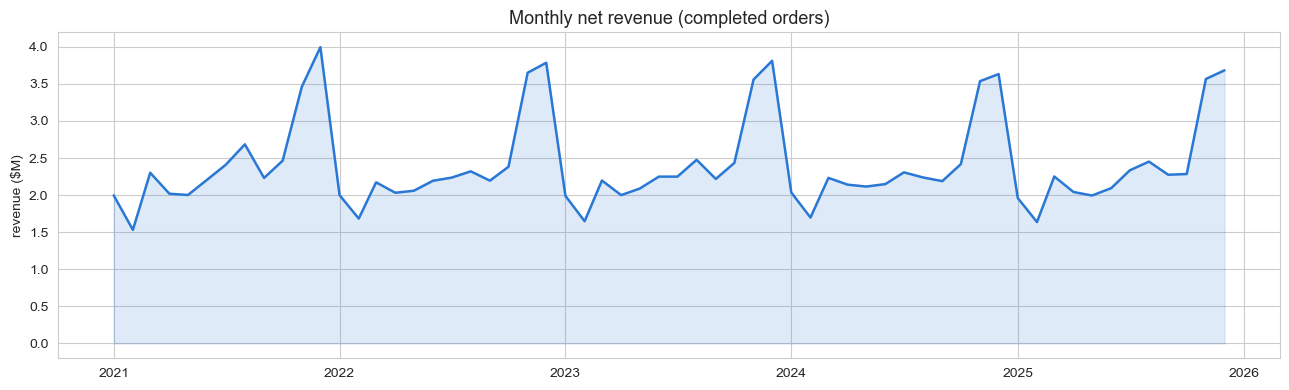

year
2021    29.3
2022    28.7
2023    28.9
2024    28.7
2025    28.6


In [10]:
m = sales.groupby('month').net_sales.sum() / 1e6
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(m.index.to_timestamp(), m.values, color=BLUE, lw=1.8)
ax.fill_between(m.index.to_timestamp(), m.values, alpha=.15, color=BLUE)
ax.set_title('Monthly net revenue (completed orders)', fontsize=13)
ax.set_ylabel('revenue ($M)'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

yr = sales.groupby('year').net_sales.sum() / 1e6
print(yr.round(1).to_string())

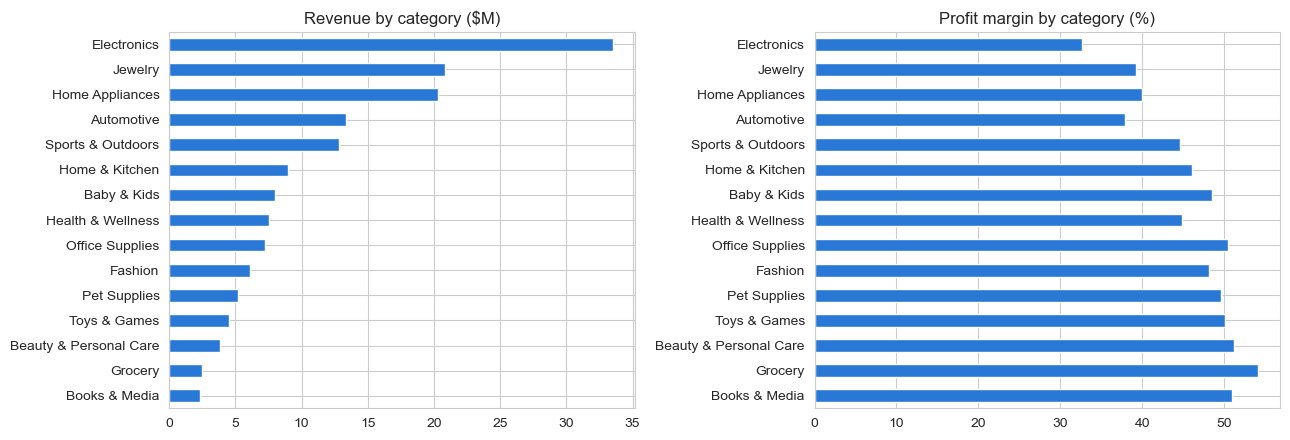

,revenue,profit,margin
product_category,,,
Electronics,33486763.0,10911604.4,32.6
Jewelry,20795540.8,8146113.5,39.2
Home Appliances,20295041.3,8097581.0,39.9
Automotive,13350204.8,5058479.5,37.9
Sports & Outdoors,12799207.1,5704263.4,44.6
Home & Kitchen,8954936.2,4126378.7,46.1
Baby & Kids,7964048.0,3861445.8,48.5
Health & Wellness,7522138.0,3374175.8,44.9
Office Supplies,7235943.6,3650995.7,50.5


In [11]:
cat = (item_sales.groupby('product_category')
       .agg(revenue=('net_sales','sum'), profit=('profit','sum'))
       .assign(margin=lambda d: d.profit/d.revenue*100)
       .sort_values('revenue', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
(cat.revenue/1e6).plot.barh(ax=axes[0], color=BLUE)
axes[0].invert_yaxis(); axes[0].set_title('Revenue by category ($M)'); axes[0].set_ylabel('')
cat.margin.plot.barh(ax=axes[1], color=BLUE)
axes[1].invert_yaxis(); axes[1].set_title('Profit margin by category (%)'); axes[1].set_ylabel('')
plt.tight_layout(); plt.show()
cat.round(1)

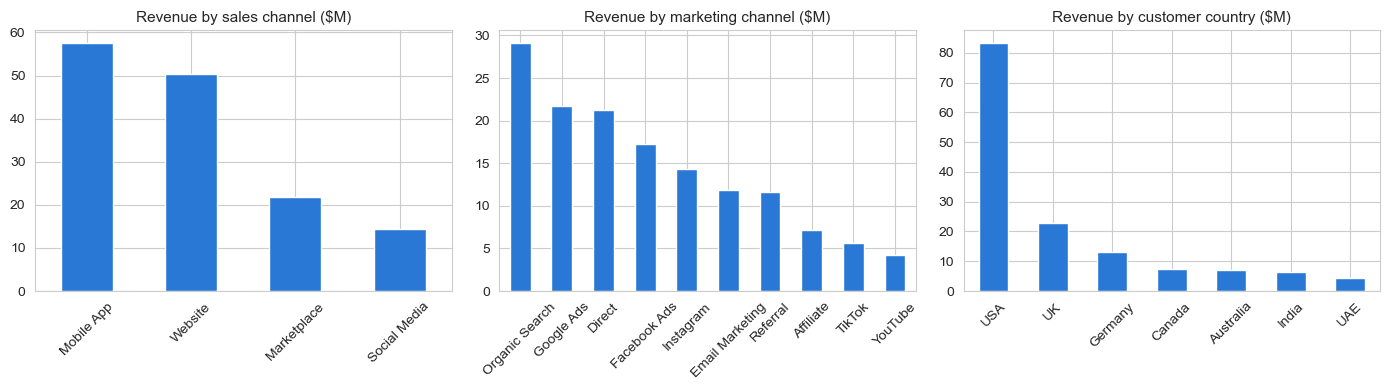

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['sales_channel', 'marketing_channel', 'customer_country']):
    s = (sales.groupby(col).net_sales.sum().sort_values(ascending=False) / 1e6)
    s.plot.bar(ax=ax, color=BLUE)
    ax.set_title(f'Revenue by {col.replace("_"," ")} ($M)', fontsize=11)
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

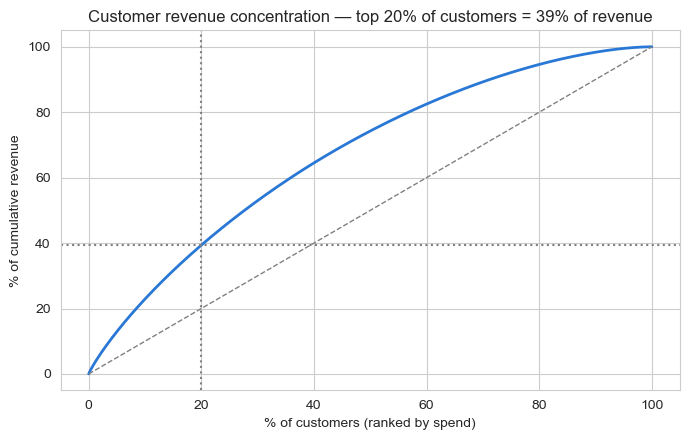

In [13]:
# Pareto: how concentrated is revenue across customers?
cust_rev = sales.groupby('customer_id').net_sales.sum().sort_values(ascending=False)
cum = cust_rev.cumsum() / cust_rev.sum()
x = np.arange(1, len(cum) + 1) / len(cum)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x * 100, cum.values * 100, color=BLUE, lw=2)
ax.plot([0, 100], [0, 100], ls='--', c='gray', lw=1)
top20 = cum.values[int(len(cum) * .2) - 1] * 100
ax.axvline(20, ls=':', c='gray'); ax.axhline(top20, ls=':', c='gray')
ax.set_title(f'Customer revenue concentration — top 20% of customers = {top20:.0f}% of revenue')
ax.set_xlabel('% of customers (ranked by spend)'); ax.set_ylabel('% of cumulative revenue')
plt.tight_layout(); plt.show()

## Cohort analysis — does the store retain customers?

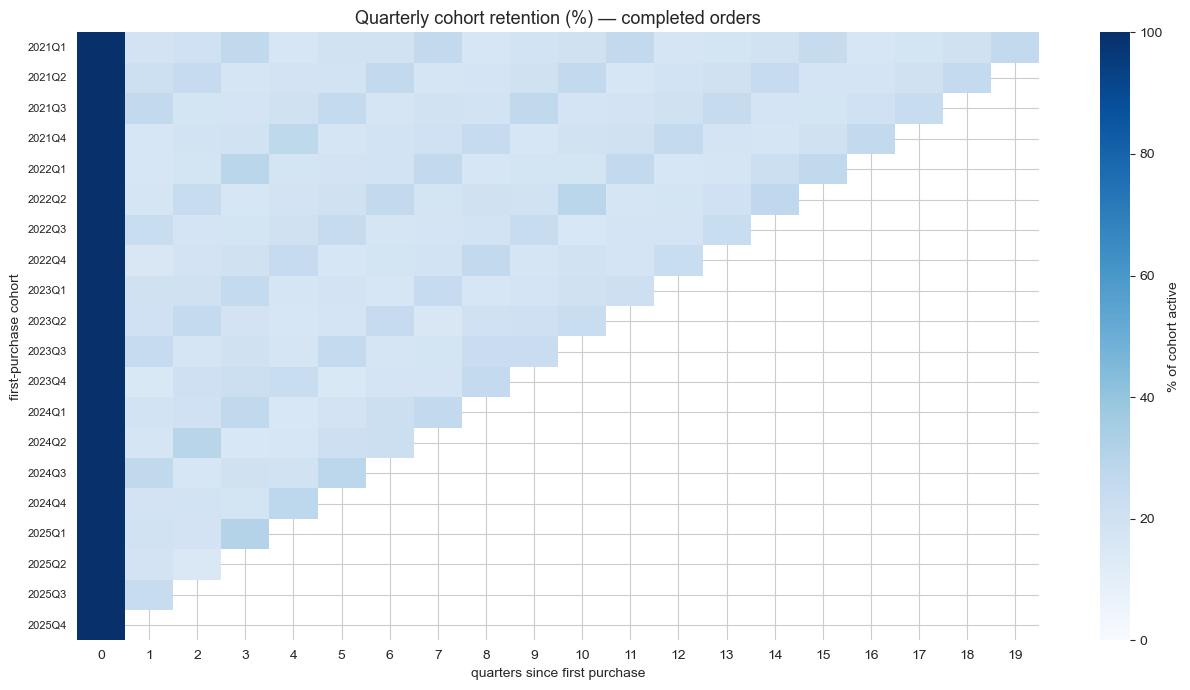

In [14]:
first_q = sales.groupby('customer_id')['quarter'].min().rename('cohort')
sc = sales.join(first_q, on='customer_id')
sc['period_no'] = (sc.quarter - sc.cohort).apply(lambda d: d.n)

cohort_active = sc.groupby(['cohort', 'period_no']).customer_id.nunique().unstack()
cohort_size = cohort_active[0]
retention = cohort_active.div(cohort_size, axis=0)

fig, ax = plt.subplots(figsize=(13, 7))
sns.heatmap(retention * 100, cmap='Blues', vmin=0, vmax=100,
            cbar_kws={'label': '% of cohort active'}, ax=ax)
ax.set_title('Quarterly cohort retention (%) — completed orders', fontsize=13)
ax.set_xlabel('quarters since first purchase')
ax.set_ylabel('first-purchase cohort')
ax.set_yticklabels([str(p) for p in retention.index], rotation=0, fontsize=8)
plt.tight_layout(); plt.show()

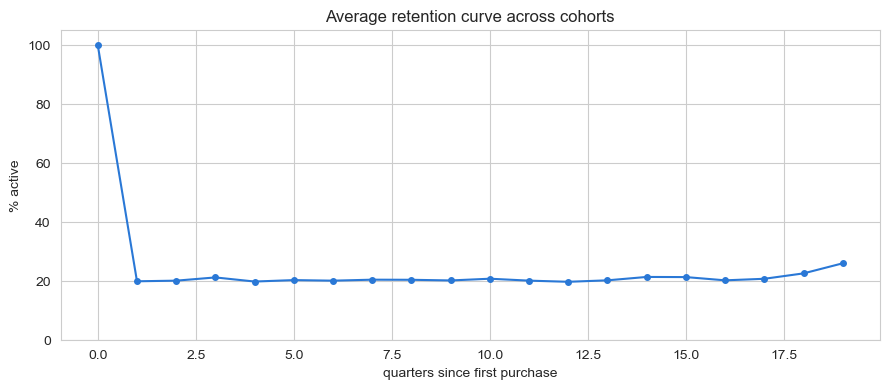

quarter 1 retention: 20%   quarter 4: 20%   quarter 8: 21%


In [15]:
avg_curve = retention.mean(axis=0) * 100
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(avg_curve.index, avg_curve.values, marker='o', ms=4, color=BLUE)
ax.set_title('Average retention curve across cohorts')
ax.set_xlabel('quarters since first purchase'); ax.set_ylabel('% active')
ax.set_ylim(0, 105)
plt.tight_layout(); plt.show()
print(f"quarter 1 retention: {avg_curve.get(1, float('nan')):.0f}%   "
      f"quarter 4: {avg_curve.get(4, float('nan')):.0f}%   quarter 8: {avg_curve.get(8, float('nan')):.0f}%")

##  RFM segmentation — who are your customers?

In [16]:
snapshot = sales.order_date.max() + pd.Timedelta(days=1)
rfm = sales.groupby('customer_id').agg(
    recency=('order_date', lambda d: (snapshot - d.max()).days),
    frequency=('order_id', 'nunique'),
    monetary=('net_sales', 'sum'))

# rank first so qcut never hits duplicate bin edges (frequency is heavily tied)
rfm['R'] = pd.qcut(rfm.recency.rank(method='first'), 5, labels=[5,4,3,2,1]).astype(int)
rfm['F'] = pd.qcut(rfm.frequency.rank(method='first'), 5, labels=[1,2,3,4,5]).astype(int)
rfm['M'] = pd.qcut(rfm.monetary.rank(method='first'), 5, labels=[1,2,3,4,5]).astype(int)

def segment(r):
    if r.R >= 4 and r.F >= 4: return 'Champions'
    if r.R >= 3 and r.F >= 3: return 'Loyal'
    if r.R >= 4 and r.F <= 2: return 'Recent / promising'
    if r.R <= 2 and r.F >= 4: return 'At risk (were loyal)'
    if r.R <= 2 and r.F <= 2: return 'Hibernating'
    return 'Need attention'
rfm['segment'] = rfm.apply(segment, axis=1)
rfm.head()

,recency,frequency,monetary,R,F,M,segment
customer_id,,,,,,,
CUST-000001,7,7,9370.54,5,5,5,Champions
CUST-000002,315,7,12713.84,3,5,5,Loyal
CUST-000003,210,6,7664.59,3,4,4,Loyal
CUST-000004,55,4,7382.98,5,2,4,Recent / promising
CUST-000005,413,8,10063.97,2,5,5,At risk (were loyal)


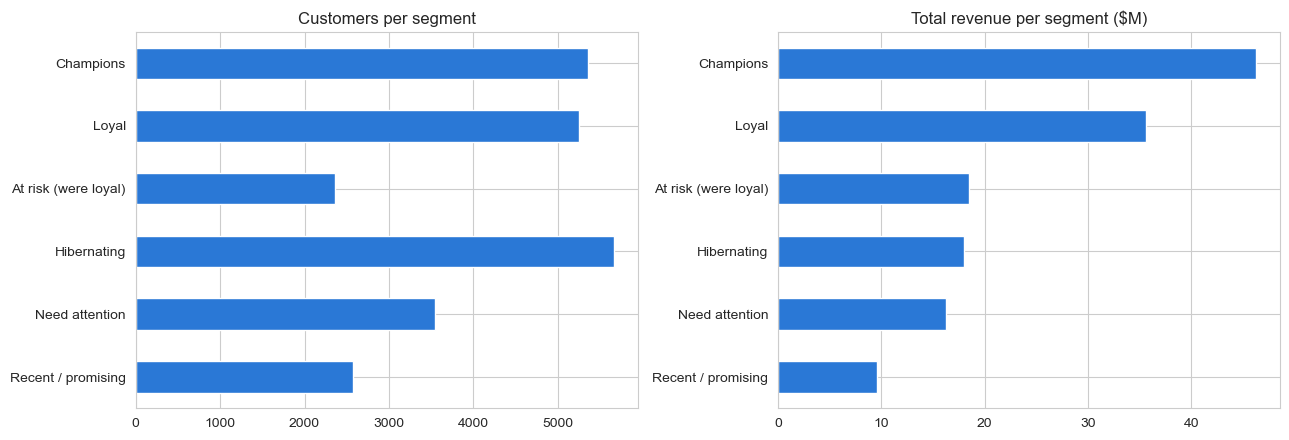

,customers,avg_spend,total_spend,avg_recency_days
segment,,,,
Champions,5356,8642.0,46289052.0,72.0
Loyal,5253,6779.0,35607764.0,192.0
At risk (were loyal),2358,7833.0,18469199.0,553.0
Hibernating,5659,3173.0,17956375.0,796.0
Need attention,3550,4584.0,16273172.0,455.0
Recent / promising,2572,3733.0,9600276.0,78.0


In [17]:
seg = (rfm.groupby('segment')
       .agg(customers=('segment','size'), avg_spend=('monetary','mean'),
            total_spend=('monetary','sum'), avg_recency_days=('recency','mean'))
       .sort_values('total_spend', ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
seg.customers.plot.barh(ax=axes[0], color=BLUE)
axes[0].invert_yaxis(); axes[0].set_title('Customers per segment'); axes[0].set_ylabel('')
(seg.total_spend/1e6).plot.barh(ax=axes[1], color=BLUE)
axes[1].invert_yaxis(); axes[1].set_title('Total revenue per segment ($M)'); axes[1].set_ylabel('')
plt.tight_layout(); plt.show()
seg.round(0)

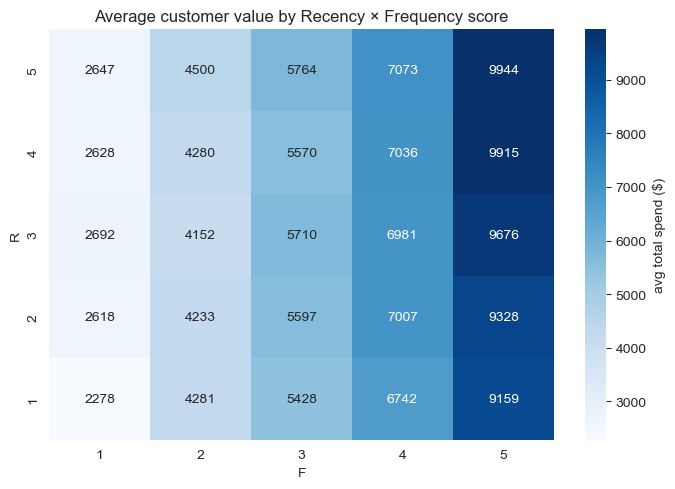

In [18]:
pivot = rfm.pivot_table(index='R', columns='F', values='monetary', aggfunc='mean')
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pivot, cmap='Blues', annot=True, fmt='.0f',
            cbar_kws={'label': 'avg total spend ($)'}, ax=ax)
ax.invert_yaxis()
ax.set_title('Average customer value by Recency × Frequency score')
plt.tight_layout(); plt.show()

## Customer Lifetime Value

In [19]:
hist = sales.groupby('customer_id').agg(
    profit_total=('profit','sum'), orders=('order_id','nunique'),
    first=('order_date','min'), last=('order_date','max'))
hist['tenure_yrs'] = ((hist['last'] - hist['first']).dt.days / 365.25).clip(lower=1/12)

avg_order_profit = sales.profit.sum() / len(sales)
freq_per_year = (hist.orders / hist.tenure_yrs).median()
q_ret = float((retention.mean(axis=0)).iloc[1:9].mean())   # steady-state quarterly retention
expected_lifetime_yrs = (1 / (1 - q_ret)) / 4              # geometric expectation, in years

clv_pred = avg_order_profit * freq_per_year * expected_lifetime_yrs
cac = customers.customer_acquisition_cost.mean()
print(f"avg profit per order        : ${avg_order_profit:,.0f}")
print(f"median orders per year      : {freq_per_year:.2f}")
print(f"steady-state qtr retention  : {q_ret:.0%}  ->  expected lifetime ~{expected_lifetime_yrs:.1f} years")
print(f"predictive CLV (formula)    : ${clv_pred:,.0f}")
print(f"average acquisition cost    : ${cac:,.0f}   ->  CLV/CAC = {clv_pred/cac:,.0f}x")

avg profit per order        : $526
median orders per year      : 1.61
steady-state qtr retention  : 20%  ->  expected lifetime ~0.3 years
predictive CLV (formula)    : $266
average acquisition cost    : $42   ->  CLV/CAC = 6x


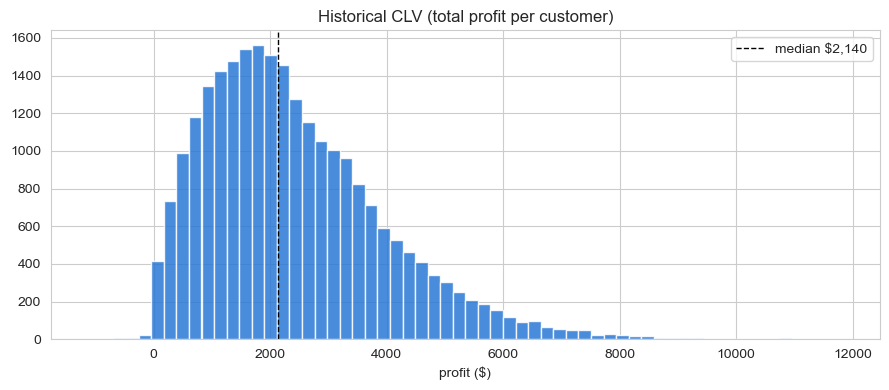

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(hist.profit_total, bins=60, color=BLUE, alpha=.85)
ax.axvline(hist.profit_total.median(), color='k', ls='--', lw=1,
           label=f'median ${hist.profit_total.median():,.0f}')
ax.set_title('Historical CLV (total profit per customer)')
ax.set_xlabel('profit ($)'); ax.legend()
plt.tight_layout(); plt.show()

In [21]:
# sanity-check the dataset's own 'customer_lifetime_value' column against reality
given = orders.groupby('customer_id').customer_lifetime_value.first()
both = hist.join(given)
corr = both.profit_total.corr(both.customer_lifetime_value)
print(f"correlation between the provided CLV column and actual per-customer profit: {corr:.3f}")

correlation between the provided CLV column and actual per-customer profit: 0.814


## Churn modelling — with an honest evaluation

In [23]:
CUTOFF = pd.Timestamp('2025-07-01')
past = sales[sales.order_date < CUTOFF]
future = sales[sales.order_date >= CUTOFF]

base = past.groupby('customer_id').agg(
    recency=('order_date', lambda d: (CUTOFF - d.max()).days),
    tenure=('order_date', lambda d: (CUTOFF - d.min()).days),
    frequency=('order_id', 'nunique'),
    monetary=('net_sales', 'sum'),
    avg_order=('net_sales', 'mean'),
    avg_rating=('customer_rating', 'mean'),
    avg_discount=('discount_amount', 'mean'),
    avg_delivery=('delivery_days', 'mean'))
ret_rate = (orders[(orders.order_date < CUTOFF)].assign(ret=lambda d: d.order_status.eq('Returned'))
            .groupby('customer_id').ret.mean())
base['return_rate'] = ret_rate.reindex(base.index).fillna(0)
base['orders_per_yr'] = base.frequency / (base.tenure / 365.25).clip(lower=1/12)
base['churn'] = (~base.index.isin(future.customer_id.unique())).astype(int)
base = base.fillna(base.median(numeric_only=True))
print(base.shape, '| churn rate:', f"{base.churn.mean():.1%}")


(24570, 11) | churn rate: 59.9%


Logistic regression     ROC-AUC 0.5049   PR-AUC 0.6049   (prevalence 0.599)


  File "C:\Users\ayush\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\ayush\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ayush\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ayush\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


Gradient boosting       ROC-AUC 0.4864   PR-AUC 0.5904   (prevalence 0.599)


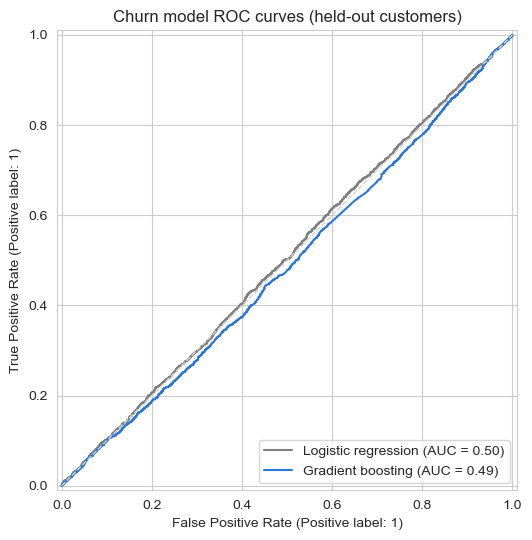

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay

X = base.drop(columns='churn'); y = base.churn
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=42, stratify=y)

models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    'Gradient boosting': HistGradientBoostingClassifier(random_state=42),
}
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, mdl in models.items():
    mdl.fit(Xtr, ytr)
    p = mdl.predict_proba(Xte)[:, 1]
    print(f"{name:22s}  ROC-AUC {roc_auc_score(yte, p):.4f}   "
          f"PR-AUC {average_precision_score(yte, p):.4f}   (prevalence {yte.mean():.3f})")
    RocCurveDisplay.from_predictions(yte, p, name=name, ax=ax,
                                     color=BLUE if 'Gradient' in name else 'gray')
ax.plot([0,1],[0,1], ls='--', c='lightgray', lw=1)
ax.set_title('Churn model ROC curves (held-out customers)')
plt.tight_layout(); plt.show()

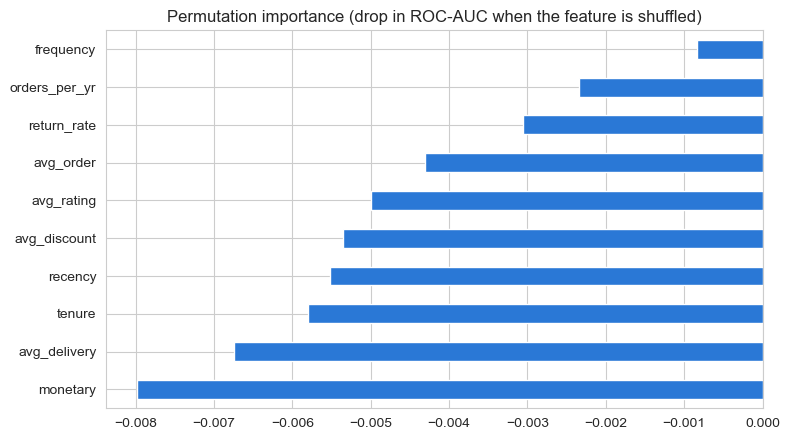

In [25]:
from sklearn.inspection import permutation_importance
gb = models['Gradient boosting']
imp = permutation_importance(gb, Xte, yte, n_repeats=10, random_state=42, scoring='roc_auc')
imp_s = pd.Series(imp.importances_mean, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
imp_s.plot.barh(ax=ax, color=BLUE)
ax.set_title('Permutation importance (drop in ROC-AUC when the feature is shuffled)')
plt.tight_layout(); plt.show()